In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

Urządzenie: cpu


In [ ]:
def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1*np.sin(3*t) + 0.05*np.random.randn(n)
    return y.astype(np.float32)

def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria)-okno):
        X.append(seria[i:i+okno])
        Y.append(seria[i+okno])
    X = np.array(X, dtype=np.float32)[..., None]  
    Y = np.array(Y, dtype=np.float32)[:, None]     
    return X, Y

class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])   

def licz_parametry(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [3]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist_tr = []
    hist_te = []
    n = len(Xtr)
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n)
        epoch_loss = 0.0
        batches = 0
        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            epoch_loss += loss.item()
            batches += 1
        hist_tr.append(epoch_loss / batches)

        model.eval()
        with torch.no_grad():
            hist_te.append(strata(model(Xte), Yte).item())
    return hist_tr, hist_te

In [4]:
seria = generuj_szereg()

In [6]:
OKNO_bazowe = 30
X, Y = zrob_okna(seria, OKNO_bazowe)
n_tr = int(0.8 * len(X))
Xtr = torch.tensor(X[:n_tr]).to(DEVICE)
Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
Xte = torch.tensor(X[n_tr:]).to(DEVICE)
Yte = torch.tensor(Y[n_tr:]).to(DEVICE)

In [7]:
heurystyka_mse = ((Yte - Xte[:, -1]) ** 2).mean().item()
print(f"Test MSE heurystyki 'ostatnia próbka': {heurystyka_mse:.5f}")

Test MSE heurystyki 'ostatnia próbka': 0.00641


In [8]:
torch.manual_seed(0); np.random.seed(0)
model_bazowy = ModelRNN(hidden=32, typ='RNN')
start_time = time.time()
hist_tr_b, hist_te_b = trenuj(model_bazowy, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64)
czas_bazowy = time.time() - start_time

mse_bazowe_srednia = np.mean(hist_te_b[-5:])
print(f"Model bazowy - Parametry: {licz_parametry(model_bazowy)}, Test MSE (ostatnie 5 epok): {mse_bazowe_srednia:.5f}, Czas: {czas_bazowy:.2f}s")

Model bazowy - Parametry: 1153, Test MSE (ostatnie 5 epok): 0.00409, Czas: 10.40s


In [9]:
wyniki_A = []
konfiguracje_A = [8, 16, 32, 64]

for hidden in konfiguracje_A:
    mse_runs = []
    czasy_runs = []
    for seed in [0, 1, 2]:
        torch.manual_seed(seed); np.random.seed(seed)
        model = ModelRNN(hidden=hidden, typ='GRU')
        param_count = licz_parametry(model)

        start = time.time()
        _, hist_te = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64)
        czas = time.time() - start

        koncowe_mse = np.mean(hist_te[-5:])
        mse_runs.append(koncowe_mse)
        czasy_runs.append(czas)

    s_mse, std_mse = np.mean(mse_runs), np.std(mse_runs)
    s_czas = np.mean(czasy_runs)
    wyniki_A.append((f"GRU, h={hidden}", param_count, f"{s_mse:.5f} ± {std_mse:.5f}", f"{s_czas:.2f}s"))
    print(f"Eksperyment A [hidden={hidden}] -> MSE: {s_mse:.5f} ± {std_mse:.5f}")

Eksperyment A [hidden=8] -> MSE: 0.00395 ± 0.00009
Eksperyment A [hidden=16] -> MSE: 0.00373 ± 0.00002
Eksperyment A [hidden=32] -> MSE: 0.00395 ± 0.00005
Eksperyment A [hidden=64] -> MSE: 0.00374 ± 0.00012


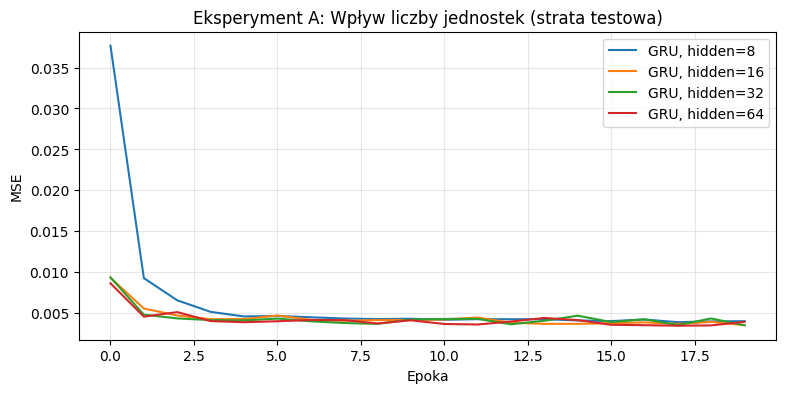

In [12]:
plt.figure(figsize=(9, 4))
for hidden in [8, 16, 32, 64]:
    torch.manual_seed(0); np.random.seed(0)
    model = ModelRNN(hidden=hidden, typ='GRU')
    _, hist_te = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20)
    plt.plot(hist_te, label=f'GRU, hidden={hidden}')
plt.title('Eksperyment A: Wpływ liczby jednostek (strata testowa)')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
wyniki_B = []
okna_B = [10, 30, 60, 120]

for okno in okna_B:
    # Ponowne utworzenie okien i podziału danych
    X_b, Y_b = zrob_okna(seria, okno)
    n_tr_b = int(0.8 * len(X_b))
    Xtr_b = torch.tensor(X_b[:n_tr_b]).to(DEVICE)
    Ytr_b = torch.tensor(Y_b[:n_tr_b]).to(DEVICE)
    Xte_b = torch.tensor(X_b[n_tr_b:]).to(DEVICE)
    Yte_b = torch.tensor(Y_b[n_tr_b:]).to(DEVICE)

    mse_runs = []
    czasy_runs = []
    for seed in [0, 1, 2]:
        torch.manual_seed(seed); np.random.seed(seed)
        model = ModelRNN(hidden=32, typ='GRU')
        param_count = licz_parametry(model)

        start = time.time()
        _, hist_te = trenuj(model, Xtr_b, Ytr_b, Xte_b, Yte_b, epoki=20, lr=1e-2, batch=64)
        czas = time.time() - start

        koncowe_mse = np.mean(hist_te[-5:])
        mse_runs.append(koncowe_mse)
        czasy_runs.append(czas)

    s_mse, std_mse = np.mean(mse_runs), np.std(mse_runs)
    s_czas = np.mean(czasy_runs)
    wyniki_B.append((f"GRU, OKNO={okno}", param_count, f"{s_mse:.5f} ± {std_mse:.5f}", f"{s_czas:.2f}s"))
    print(f"Eksperyment B [OKNO={okno}] -> MSE: {s_mse:.5f} ± {std_mse:.5f}")

Eksperyment B [OKNO=10] -> MSE: 0.00454 ± 0.00017
Eksperyment B [OKNO=30] -> MSE: 0.00395 ± 0.00005
Eksperyment B [OKNO=60] -> MSE: 0.00356 ± 0.00002
Eksperyment B [OKNO=120] -> MSE: 0.00355 ± 0.00019


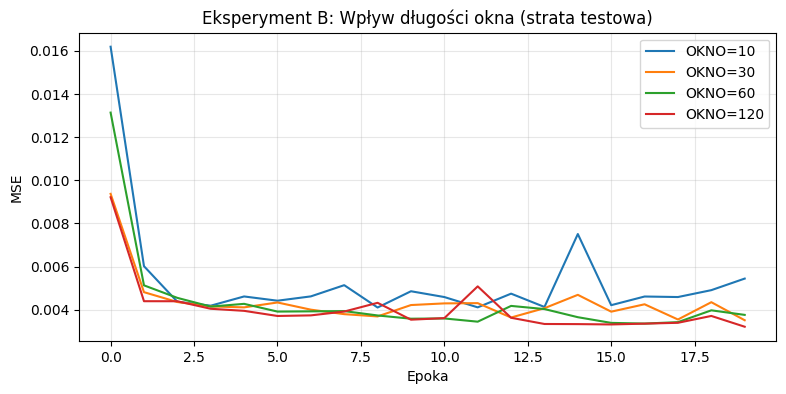

In [13]:
plt.figure(figsize=(9, 4))
for okno in [10, 30, 60, 120]:
    X_b, Y_b = zrob_okna(seria, okno)
    n_tr_b = int(0.8 * len(X_b))
    Xtr_b = torch.tensor(X_b[:n_tr_b]).to(DEVICE)
    Ytr_b = torch.tensor(Y_b[:n_tr_b]).to(DEVICE)
    Xte_b = torch.tensor(X_b[n_tr_b:]).to(DEVICE)
    Yte_b = torch.tensor(Y_b[n_tr_b:]).to(DEVICE)

    torch.manual_seed(0); np.random.seed(0)
    model = ModelRNN(hidden=32, typ='GRU')
    _, hist_te = trenuj(model, Xtr_b, Ytr_b, Xte_b, Yte_b, epoki=20)
    plt.plot(hist_te, label=f'OKNO={okno}')
plt.title('Eksperyment B: Wpływ długości okna (strata testowa)')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
wyniki_C = []
skrajne_okna = [10, 120]
typy_komorek = ['RNN', 'LSTM', 'GRU']

for okno in skrajne_okna:
    X_c, Y_c = zrob_okna(seria, okno)
    n_tr_c = int(0.8 * len(X_c))
    Xtr_c = torch.tensor(X_c[:n_tr_c]).to(DEVICE)
    Ytr_c = torch.tensor(Y_c[:n_tr_c]).to(DEVICE)
    Xte_c = torch.tensor(X_c[n_tr_c:]).to(DEVICE)
    Yte_c = torch.tensor(Y_c[n_tr_c:]).to(DEVICE)

    for typ in typy_komorek:
        mse_runs = []
        czasy_runs = []
        for seed in [0, 1, 2]:
            torch.manual_seed(seed); np.random.seed(seed)
            model = ModelRNN(hidden=32, typ=typ)
            param_count = licz_parametry(model)

            start = time.time()
            _, hist_te = trenuj(model, Xtr_c, Ytr_c, Xte_c, Yte_c, epoki=20, lr=1e-2, batch=64)
            czas = time.time() - start

            koncowe_mse = np.mean(hist_te[-5:])
            mse_runs.append(koncowe_mse)
            czasy_runs.append(czas)

        s_mse, std_mse = np.mean(mse_runs), np.std(mse_runs)
        s_czas = np.mean(czasy_runs)
        wyniki_C.append((f"{typ}, OKNO={okno}", param_count, f"{s_mse:.5f} ± {std_mse:.5f}", f"{s_czas:.2f}s"))
        print(f"Eksperyment C [{typ}, OKNO={okno}] -> MSE: {s_mse:.5f} ± {std_mse:.5f}")

Eksperyment C [RNN, OKNO=10] -> MSE: 0.00454 ± 0.00030
Eksperyment C [LSTM, OKNO=10] -> MSE: 0.00446 ± 0.00011
Eksperyment C [GRU, OKNO=10] -> MSE: 0.00454 ± 0.00017
Eksperyment C [RNN, OKNO=120] -> MSE: 0.00432 ± 0.00024
Eksperyment C [LSTM, OKNO=120] -> MSE: 0.00382 ± 0.00006
Eksperyment C [GRU, OKNO=120] -> MSE: 0.00355 ± 0.00019


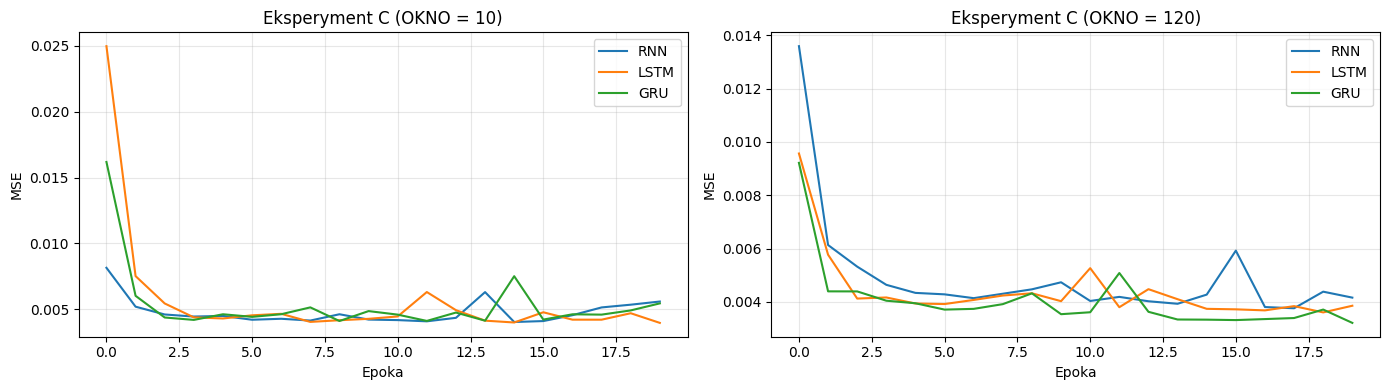

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for idx, okno in enumerate([10, 120]):
    X_c, Y_c = zrob_okna(seria, okno)
    n_tr_c = int(0.8 * len(X_c))
    Xtr_c = torch.tensor(X_c[:n_tr_c]).to(DEVICE)
    Ytr_c = torch.tensor(Y_c[:n_tr_c]).to(DEVICE)
    Xte_c = torch.tensor(X_c[n_tr_c:]).to(DEVICE)
    Yte_c = torch.tensor(Y_c[n_tr_c:]).to(DEVICE)

    for typ in ['RNN', 'LSTM', 'GRU']:
        torch.manual_seed(0); np.random.seed(0)
        model = ModelRNN(hidden=32, typ=typ)
        _, hist_te = trenuj(model, Xtr_c, Ytr_c, Xte_c, Yte_c, epoki=20)
        axes[idx].plot(hist_te, label=typ)
    axes[idx].set_title(f'Eksperyment C (OKNO = {okno})')
    axes[idx].set_xlabel('Epoka')
    axes[idx].set_ylabel('MSE')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

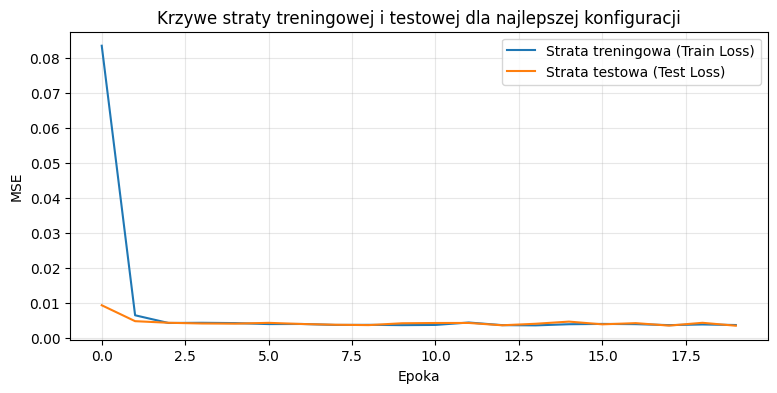

In [15]:
torch.manual_seed(0); np.random.seed(0)
najlepszy_model = ModelRNN(hidden=32, typ='GRU')
hist_tr_best, hist_te_best = trenuj(najlepszy_model, Xtr, Ytr, Xte, Yte, epoki=20)

plt.figure(figsize=(9, 4))
plt.plot(hist_tr_best, label='Strata treningowa (Train Loss)')
plt.plot(hist_te_best, label='Strata testowa (Test Loss)')
plt.title('Krzywe straty treningowej i testowej dla najlepszej konfiguracji')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

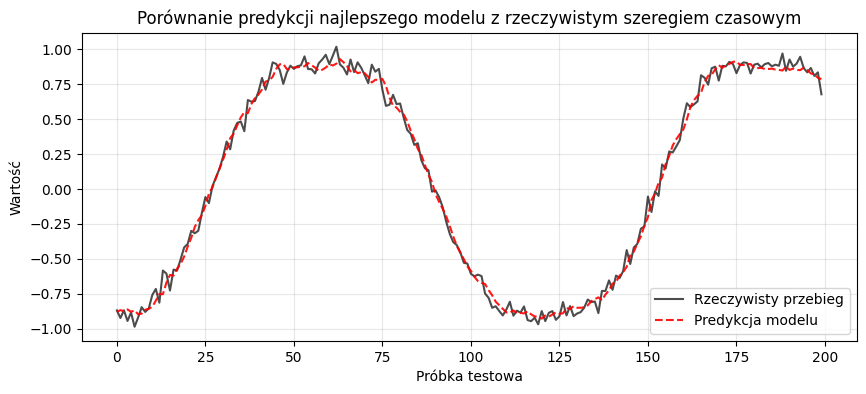

In [16]:
najlepszy_model.eval()
with torch.no_grad():
    pred_best = najlepszy_model(Xte).cpu().numpy().ravel()
prawdziwe_best = Yte.cpu().numpy().ravel()

plt.figure(figsize=(10, 4))
plt.plot(prawdziwe_best[:200], label='Rzeczywisty przebieg', color='black', alpha=0.7)
plt.plot(pred_best[:200], label='Predykcja modelu', color='red', linestyle='--', alpha=0.9)
plt.title('Porównanie predykcji najlepszego modelu z rzeczywistym szeregiem czasowym')
plt.xlabel('Próbka testowa')
plt.ylabel('Wartość')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()